In [1]:

import numpy as np
import pandas as pd
from pathlib import Path

# Load processed Titanic data
data_path = Path("/kaggle/input")

train = pd.read_csv(next(data_path.rglob("titanic_train_processed.csv")))
test = pd.read_csv(next(data_path.rglob("titanic_test_processed.csv")))

# Separate features and labels
X_train = train.drop(columns="Survived").values
y_train = train["Survived"].values

X_test = test.drop(columns="Survived").values
y_test = test["Survived"].values

print("Training:", X_train.shape, y_train.shape)
print("Testing:", X_test.shape, y_test.shape)


Training: (712, 10) (712,)
Testing: (179, 10) (179,)


In [2]:

# Logistic Regression using SGD + Momentum

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

X = np.c_[np.ones(len(X_train)), X_train]

weights = np.zeros(X.shape[1])
velocity = np.zeros_like(weights)

lr = 0.001
momentum = 0.9
epochs = 200
loss_history = []
rng = np.random.default_rng(42)

for epoch in range(epochs):
    for i in rng.permutation(len(X)):
        xi = X[i]
        yi = y_train[i]

        prediction = sigmoid(xi @ weights)
        gradient = xi * (prediction - yi)

        velocity = momentum * velocity + gradient
        weights -= lr * velocity

    # Calculate loss after each epoch
    p = np.clip(sigmoid(X @ weights), 1e-10, 1 - 1e-10)
    loss = -np.mean(y_train * np.log(p) +
                    (1 - y_train) * np.log(1 - p))
    loss_history.append(loss)

print("SGD + Momentum Training Completed!")
print("Final Training Loss:", loss_history[-1])
print("Learned Weights:", weights)


SGD + Momentum Training Completed!
Final Training Loss: 0.4367015999627761
Learned Weights: [-0.65991036 -0.94615259 -0.56248189 -0.24010326 -0.0447574   0.09682299
  0.65667343 -0.65667343  0.06897847  0.13505099 -0.14239249]


Accuracy : 0.7988826815642458
Precision: 0.7796610169491526
Recall   : 0.6666666666666666
F1 Score : 0.71875
Test Loss: 0.4675710099261871


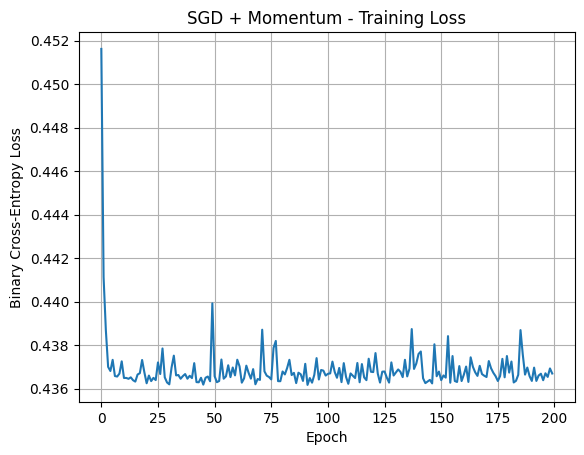

In [3]:

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt

X_test_bias = np.c_[np.ones(len(X_test)), X_test]
probs = sigmoid(X_test_bias @ weights)
y_pred = (probs >= 0.5).astype(int)

p = np.clip(probs, 1e-10, 1 - 1e-10)
test_loss = -np.mean(y_test * np.log(p) +
                     (1 - y_test) * np.log(1 - p))

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score :", f1_score(y_test, y_pred, zero_division=0))
print("Test Loss:", test_loss)

plt.plot(loss_history)
plt.title("SGD + Momentum - Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()
